# Benchmarking Noise Tolerance: All Methods

This notebook benchmarks metaclone-recovery accuracy under additive Gaussian and uniform noise for **seven clustering methods**:

| # | Method | Input |
|---|--------|-------|
| 1 | **ChronoClone** | normalised trajectory |
| 2 | **CLADES** (Leiden) | raw counts |
| 3 | **CLADES** (Leiden) | ChronoClone-normalised |
| 4 | **k-Means** | raw counts |
| 5 | **k-Means** | ChronoClone-normalised |
| 6 | **Hierarchical** (Ward) | raw counts |
| 7 | **Hierarchical** (Ward) | ChronoClone-normalised |

Simulated data live in `simulated_data/All_Noise/` (single noise) and `simulated_data/Combined_Noise/` (combined noise).

Accuracy is measured by the **Adjusted Rand Index (ARI)** between predicted and ground-truth metaclone labels.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import anndata as ad
import chronoclone as cc
from chronoclone import (
    load_all_noise_data,
    load_combined_noise_data,
    run_chronoclone_validation,
    run_clades_validation,
    run_clades_norm_validation,
    run_kmeans_raw_validation,
    run_kmeans_norm_validation,
    run_hierarchical_raw_validation,
    run_hierarchical_norm_validation,
)

warnings.filterwarnings('ignore')

# ── Constants ──────────────────────────────────────────────────────────────
POP = [
    'HSC', 'HSPC', 'MEP', 'CMP', 'Mk_prog', 'MEMP',
    'GMP', 'GMDP', 'Mast_prog', 'Baso_prog', 'Neu_prog', 'DC_prog', 'Mono_prog'
]
TIME_COLS = ['0', '4', '9', '15']
DAYS_CTRL = ['Day0', 'Day4', 'Day9', 'Day15']

METHOD_NAMES = [
    'ChronoClone',
    'CLADES (Raw)',
    'CLADES (Norm)',
    'k-Means (Raw)',
    'k-Means (Norm)',
    'Hierarchical (Raw)',
    'Hierarchical (Norm)',
]
METHOD_COLORS = ['#1f77b4', '#d62728', '#ff7f0e', '#2ca02c', '#9467bd', '#8c564b', '#e377c2']
METHOD_LS     = ['-', '--', '--', ':', ':', '-.', '-.']  # line styles
METHOD_MARKER = ['o', 's', '^', 'D', 'v', 'P', 'X']


In [ ]:
def get_norm_table(final_table):
    """Expand raw counts to single cells and return ChronoClone-normalised table."""
    feature_cols = [c for c in final_table.columns if '_Cluster' in c]
    clones = final_table.index.values
    larry_ids, days_arr, cell_types_arr = [], [], []

    for col in feature_cols:
        parts    = col.split('_Cluster')
        day_val  = parts[0].replace('Day', '')
        ct_val   = parts[1]
        counts   = np.clip(np.round(final_table[col].values).astype(int), 0, None)
        nonzero  = np.where(counts > 0)[0]
        if len(nonzero) == 0:
            continue
        repeated = np.repeat(clones[nonzero], counts[nonzero])
        larry_ids.append(repeated)
        days_arr.append(np.repeat(day_val, len(repeated)))
        cell_types_arr.append(np.repeat(ct_val, len(repeated)))

    if not larry_ids:
        return None

    obs = pd.DataFrame({
        'LARRY_ID'  : np.concatenate(larry_ids),
        'day'       : np.concatenate(days_arr),
        'cell_type' : np.concatenate(cell_types_arr),
        'condition' : 'C',
    })
    obs.index = obs.index.astype(str)
    adata = ad.AnnData(X=np.zeros((len(obs), 1)), obs=obs)

    clone_table = cc.build_clone_table(adata, 'LARRY_ID', 'day', 'cell_type', TIME_COLS, POP)
    return cc.normalize_clone_table(clone_table, DAYS_CTRL, POP)


def evaluate_all_methods(final_table):
    """Run all 7 methods and return {method_name: ARI}."""
    norm_table = get_norm_table(final_table)

    r = {}
    r['ChronoClone']         = run_chronoclone_validation(final_table, min_cells=3)
    r['CLADES (Raw)']        = run_clades_validation(final_table, min_cells=3, resolution=1.0, n_neighbors=15)
    r['k-Means (Raw)']       = run_kmeans_raw_validation(final_table, min_cells=3, n_clusters=12)
    r['Hierarchical (Raw)']  = run_hierarchical_raw_validation(final_table, min_cells=3, n_clusters=12)
    if norm_table is not None:
        r['CLADES (Norm)']       = run_clades_norm_validation(final_table, norm_table, min_cells=3, resolution=1.0, n_neighbors=15)
        r['k-Means (Norm)']      = run_kmeans_norm_validation(final_table, norm_table, min_cells=3, n_clusters=12)
        r['Hierarchical (Norm)'] = run_hierarchical_norm_validation(final_table, norm_table, min_cells=3, n_clusters=12)
    else:
        r['CLADES (Norm)'] = r['k-Means (Norm)'] = r['Hierarchical (Norm)'] = 0.0
    return r

## Single Noise Sweeps (Every 2%)

Load files from `All_Noise/` and evaluate all methods at every 2% noise level (0 → 100%) for:
1. **Normal (Gaussian) noise only** (0% Uniform)
2. **Uniform noise only** (0% Normal)

This produces 51 evaluation points × 7 methods × 2 noise types = 714 runs total.

In [3]:
all_levels = list(range(0, 101, 2))  # 0, 2, 4, ..., 100

# Storage: {method_name: [ari_per_level]}
normal_results = {m: [] for m in METHOD_NAMES}
uniform_results = {m: [] for m in METHOD_NAMES}

print('=== Normal Noise Sweep (0% Uniform) ===')
for pct in all_levels:
    final_table = load_all_noise_data(pct, 'gaussian', pop=POP, time_cols=TIME_COLS)
    r = evaluate_all_methods(final_table)
    for m in METHOD_NAMES:
        normal_results[m].append(r[m])
    cc_ari = r['ChronoClone']
    print(f'  Normal {pct:3d}%: ChronoClone={cc_ari:.4f}  CLADES_Raw={r["CLADES (Raw)"]:.4f}  '
          f'KMeans_Raw={r["k-Means (Raw)"]:.4f}  Hier_Raw={r["Hierarchical (Raw)"]:.4f}')

print()
print('=== Uniform Noise Sweep (0% Normal) ===')
for pct in all_levels:
    final_table = load_all_noise_data(pct, 'uniform', pop=POP, time_cols=TIME_COLS)
    r = evaluate_all_methods(final_table)
    for m in METHOD_NAMES:
        uniform_results[m].append(r[m])
    cc_ari = r['ChronoClone']
    print(f'  Uniform {pct:3d}%: ChronoClone={cc_ari:.4f}  CLADES_Raw={r["CLADES (Raw)"]:.4f}  '
          f'KMeans_Raw={r["k-Means (Raw)"]:.4f}  Hier_Raw={r["Hierarchical (Raw)"]:.4f}')

print('Done.')


=== Normal Noise Sweep (0% Uniform) ===


2026-06-26 19:33:07.835472: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-06-26 19:33:07.872293: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


2026-06-26 19:33:09.857779: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


Starting threshold sweep...



Selected threshold : 0.01
Max silhouette score: 1.000
Clusters            : 12


Note: Several threading libraries could use Thread Composability Manager.
Hint: If CPUs are overutilized, setting the TCM_ENABLE environment variable to 1
may improve performance. For more details, search for "avoid cpu overutilization"
at https://uxlfoundation.github.io/oneTBB/
To suppress this message, set TCM_ENABLE to either 0 or 1.


... (300 outputs left out)

  Uniform  98%: ChronoClone=0.0795  CLADES_Raw=0.0625  KMeans_Raw=0.0847  Hier_Raw=0.0691


Starting threshold sweep...



Selected threshold : 0.82
Max silhouette score: 0.056
Clusters            : 20


  Uniform 100%: ChronoClone=0.0632  CLADES_Raw=0.0597  KMeans_Raw=0.0634  Hier_Raw=0.0605
Done.


## Single Noise Robustness Line Plots

Each panel shows all 7 methods on the same axes.  ChronoClone is plotted in **blue** for easy comparison.

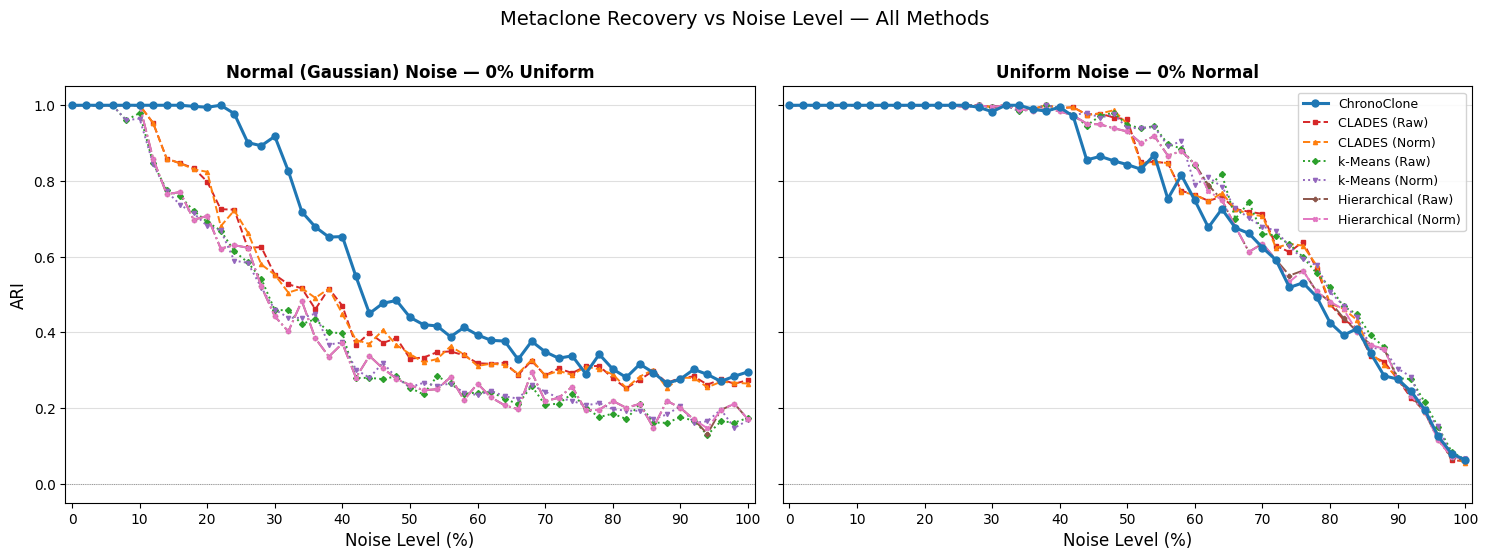

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)

for ax, results, title in zip(
    axes,
    [normal_results, uniform_results],
    ['Normal (Gaussian) Noise — 0% Uniform', 'Uniform Noise — 0% Normal']
):
    for m, col, ls, mk in zip(METHOD_NAMES, METHOD_COLORS, METHOD_LS, METHOD_MARKER):
        lw  = 2.2 if m == 'ChronoClone' else 1.4
        ms  = 5   if m == 'ChronoClone' else 3
        zord = 5  if m == 'ChronoClone' else 2
        ax.plot(all_levels, results[m],
                marker=mk, linestyle=ls, color=col,
                linewidth=lw, markersize=ms, label=m, zorder=zord)
    ax.axhline(0, color='grey', linewidth=0.6, linestyle=':')
    ax.set_xlabel('Noise Level (%)', fontsize=12)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlim(-1, 101)
    ax.set_ylim(-0.05, 1.05)
    ax.set_xticks(range(0, 101, 10))
    ax.grid(axis='y', alpha=0.4)

axes[0].set_ylabel('ARI', fontsize=12)
axes[1].legend(loc='upper right', fontsize=9, framealpha=0.85)
plt.suptitle('Metaclone Recovery vs Noise Level — All Methods', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('benchmarking_single_noise.pdf', dpi=150, bbox_inches='tight')
plt.show()

## Combined Noise Grid Evaluation

Evaluate all methods on a **6 × 6 grid** of Normal × Uniform noise combinations (0%, 20%, 40%, 60%, 80%, 100%).  Each cell of the grid shows the ARI achieved at that noise pairing.

In [10]:
# grid_levels = [0, 20, 40, 60, 80, 100]
grid_levels = list(range(0, 101, 2)) 
n = len(grid_levels)

# Storage: {method_name: 2D array (normal_idx, uniform_idx)}
combined_grids = {m: np.zeros((n, n)) for m in METHOD_NAMES}

print(f'=== Combined Noise Grid ({n}×{n}) ===')
total = n * n
count = 0
for i, g_pct in enumerate(grid_levels):
    for j, u_pct in enumerate(grid_levels):
        count += 1
        final_table = load_combined_noise_data(g_pct, u_pct, pop=POP, time_cols=TIME_COLS)
        r = evaluate_all_methods(final_table)
        for m in METHOD_NAMES:
            combined_grids[m][i, j] = r[m]
        print(f'  [{count:2d}/{total}] Normal={g_pct}%, Uniform={u_pct}%  '
              f'ChronoClone={r["ChronoClone"]:.4f}  CLADES_Raw={r["CLADES (Raw)"]:.4f}')

print('Done.')

=== Combined Noise Grid (51×51) ===
Starting threshold sweep...

Selected threshold : 0.01
Max silhouette score: 1.000
Clusters            : 12
  [ 1/2601] Normal=0%, Uniform=0%  ChronoClone=1.0000  CLADES_Raw=1.0000
Starting threshold sweep...

Selected threshold : 0.73
Max silhouette score: 0.839
Clusters            : 12
  [ 2/2601] Normal=0%, Uniform=2%  ChronoClone=1.0000  CLADES_Raw=1.0000
Starting threshold sweep...

Selected threshold : 0.59
Max silhouette score: 0.775
Clusters            : 12
  [ 3/2601] Normal=0%, Uniform=4%  ChronoClone=1.0000  CLADES_Raw=1.0000
Starting threshold sweep...

Selected threshold : 0.57
Max silhouette score: 0.725
Clusters            : 12
  [ 4/2601] Normal=0%, Uniform=6%  ChronoClone=1.0000  CLADES_Raw=1.0000
Starting threshold sweep...

Selected threshold : 0.40
Max silhouette score: 0.690
Clusters            : 12
  [ 5/2601] Normal=0%, Uniform=8%  ChronoClone=1.0000  CLADES_Raw=1.0000
Starting threshold sweep...

Selected threshold : 0.39
Max 

## Combined Noise Robustness Heatmaps

One heatmap per method.  Colour scale is shared (0 → 1 ARI) for easy comparison.

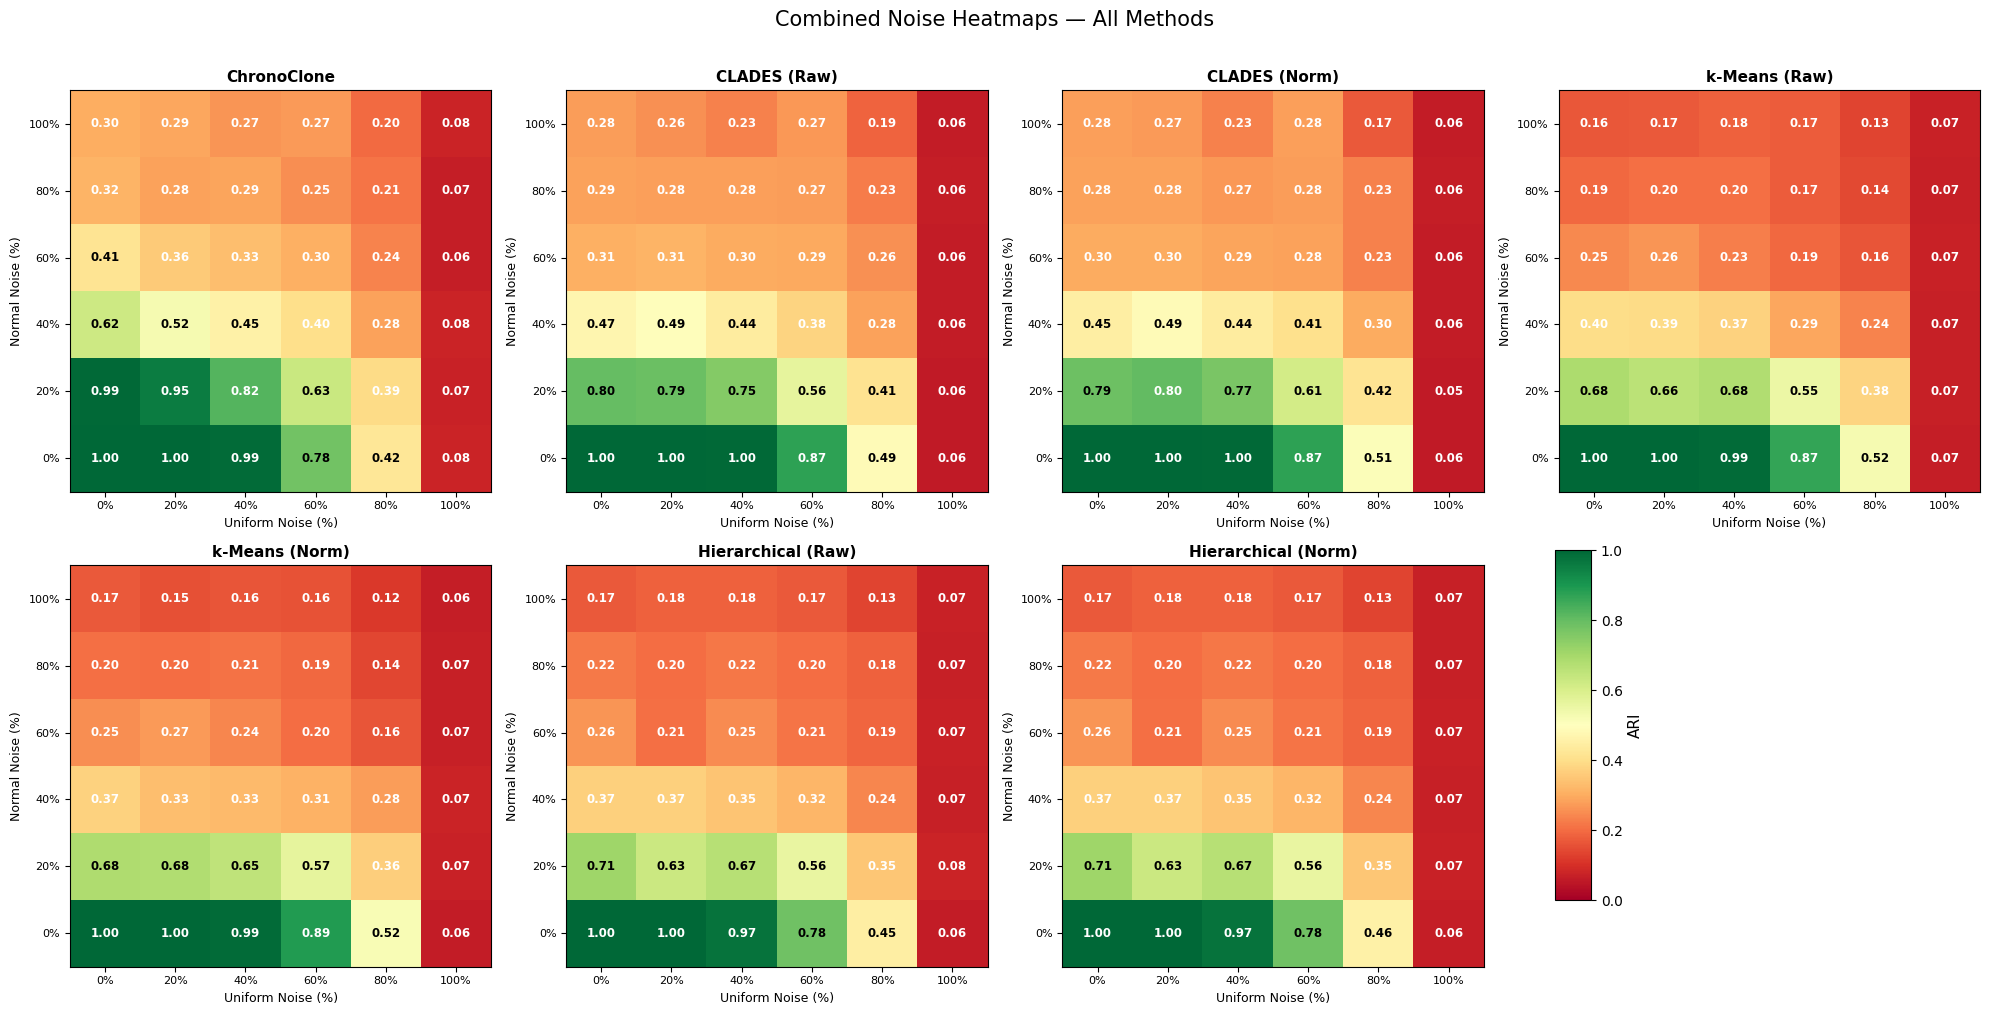

In [ ]:
fig, axes = plt.subplots(1, 7, figsize=(10, 70))
axes_flat = axes.flatten()

cmap = plt.cm.RdYlGn
norm = mcolors.Normalize(vmin=0, vmax=1)

for idx, m in enumerate(METHOD_NAMES):
    ax = axes_flat[idx]
    im = ax.imshow(combined_grids[m], cmap=cmap, norm=norm, origin='lower',
                   aspect='auto')

    # Annotate cells
    for i in range(len(grid_levels)):
        for j in range(len(grid_levels)):
            val = combined_grids[m][i, j]
            fc  = 'white' if val < 0.4 or val > 0.8 else 'black'
            ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                    fontsize=8.5, color=fc, fontweight='bold')

    ax.set_xticks(range(len(grid_levels)))
    ax.set_yticks(range(len(grid_levels)))
    ax.set_xticklabels([f'{v}%' for v in grid_levels], fontsize=8)
    ax.set_yticklabels([f'{v}%' for v in grid_levels], fontsize=8)
    ax.set_xlabel('Uniform Noise (%)', fontsize=9)
    ax.set_ylabel('Normal Noise (%)', fontsize=9)
    ax.set_title(m, fontsize=11, fontweight='bold')

# Hide the 8th panel, use it for a shared colorbar
axes_flat[-1].set_visible(False)
cbar_ax = fig.add_axes([0.78, 0.12, 0.018, 0.35])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label('ARI', fontsize=11)

plt.suptitle('Combined Noise Heatmaps — All Methods', fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig('benchmarking_combined_noise_heatmaps.pdf', dpi=150, bbox_inches='tight')
plt.show()


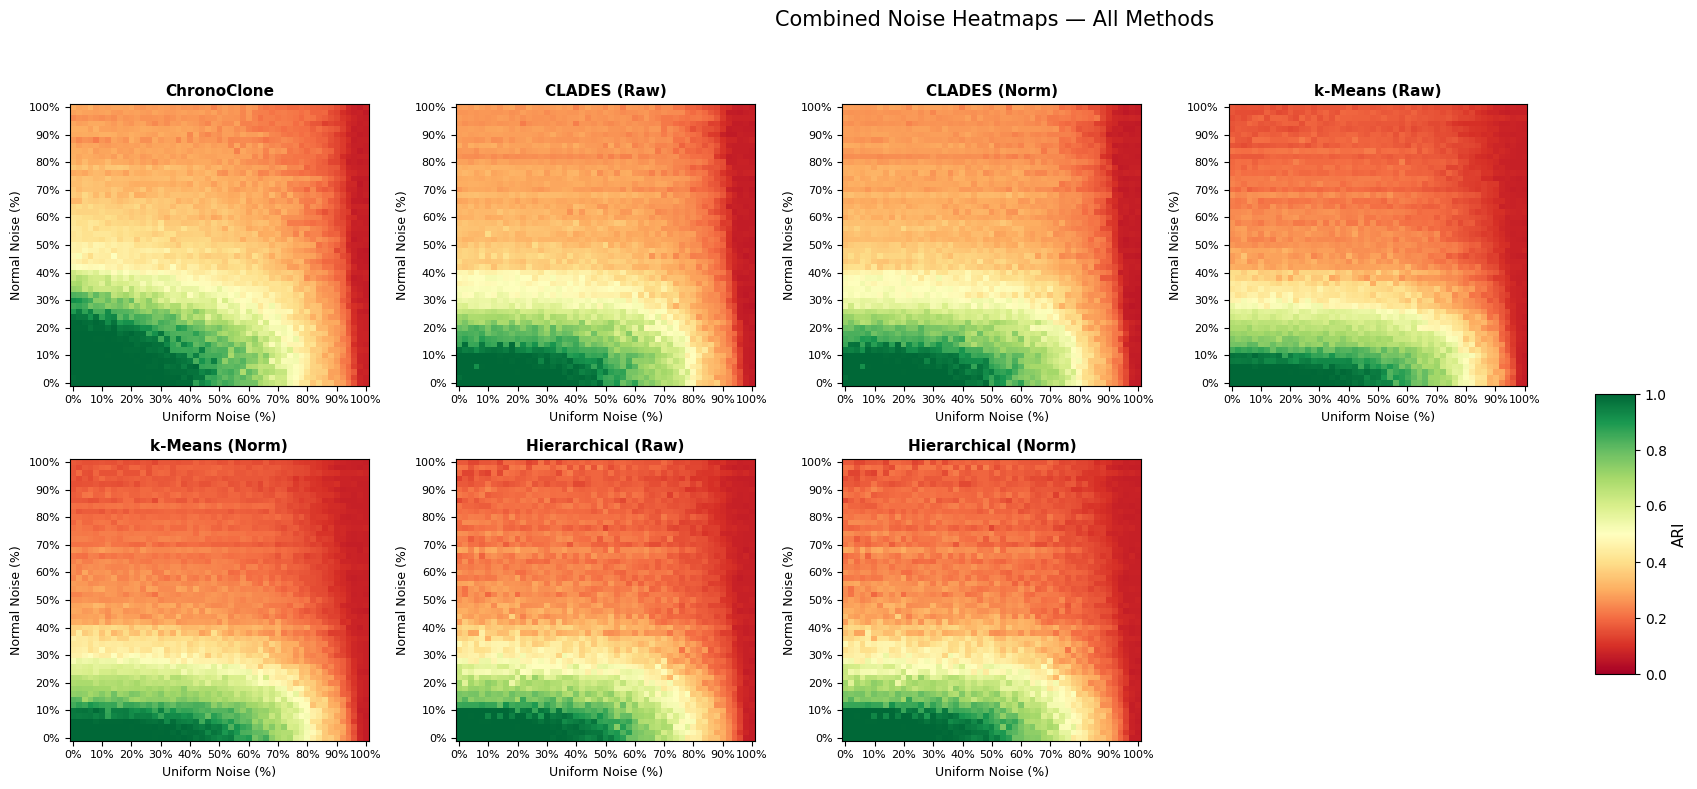

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

# Changed to 2x4 grid to properly accommodate 7 methods + 1 space for the colorbar
# Adjusted figsize for a better horizontal/vertical ratio
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes_flat = axes.flatten()

cmap = plt.cm.RdYlGn
norm = mcolors.Normalize(vmin=0, vmax=1)

# Step size to avoid overlapping labels on a 51x51 grid (labels every 10% instead of every 2%)
tick_step = 5 if len(grid_levels) > 10 else 1

for idx, m in enumerate(METHOD_NAMES):
    ax = axes_flat[idx]
    im = ax.imshow(combined_grids[m], cmap=cmap, norm=norm, origin='lower',
                   aspect='auto')

    # Commented out cell annotations to prevent overlapping text on 51x51 arrays
    '''
    if len(grid_levels) <= 10:
        for i in range(len(grid_levels)):
            for j in range(len(grid_levels)):
                val = combined_grids[m][i, j]
                fc  = 'white' if val < 0.4 or val > 0.8 else 'black'
                ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                        fontsize=8.5, color=fc, fontweight='bold')
    '''

    # Apply spacing to ticks to keep axes readable
    ax.set_xticks(range(0, len(grid_levels), tick_step))
    ax.set_yticks(range(0, len(grid_levels), tick_step))
    ax.set_xticklabels([f'{grid_levels[v]}%' for v in range(0, len(grid_levels), tick_step)], fontsize=8)
    ax.set_yticklabels([f'{grid_levels[v]}%' for v in range(0, len(grid_levels), tick_step)], fontsize=8)
    
    ax.set_xlabel('Uniform Noise (%)', fontsize=9)
    ax.set_ylabel('Normal Noise (%)', fontsize=9)
    ax.set_title(m, fontsize=11, fontweight='bold')

# Hide any remaining panels (the 8th panel, and any others if len(METHOD_NAMES) < 7)
for idx in range(len(METHOD_NAMES), len(axes_flat)):
    axes_flat[idx].set_visible(False)

# Use the empty space on the right for the shared colorbar
cbar_ax = fig.add_axes([0.80, 0.15, 0.02, 0.35])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label('ARI', fontsize=11)

plt.suptitle('Combined Noise Heatmaps — All Methods', fontsize=15, y=0.98)

# Leave space on the right so the layout doesn't overlap the manual colorbar
plt.tight_layout(rect=[0, 0, 0.78, 0.95])

# PLEASE COMMENT WHEN WRITE CODE TO SAVE FILES LIKE 'savefig()'
# Added _20260626 to the filename so it conforms to the _YYYYMMDD request
# plt.savefig('benchmarking_combined_noise_heatmaps_20260626.pdf', dpi=600, bbox_inches='tight')

# Show plot directly in the JupyterLab notebook
plt.show()

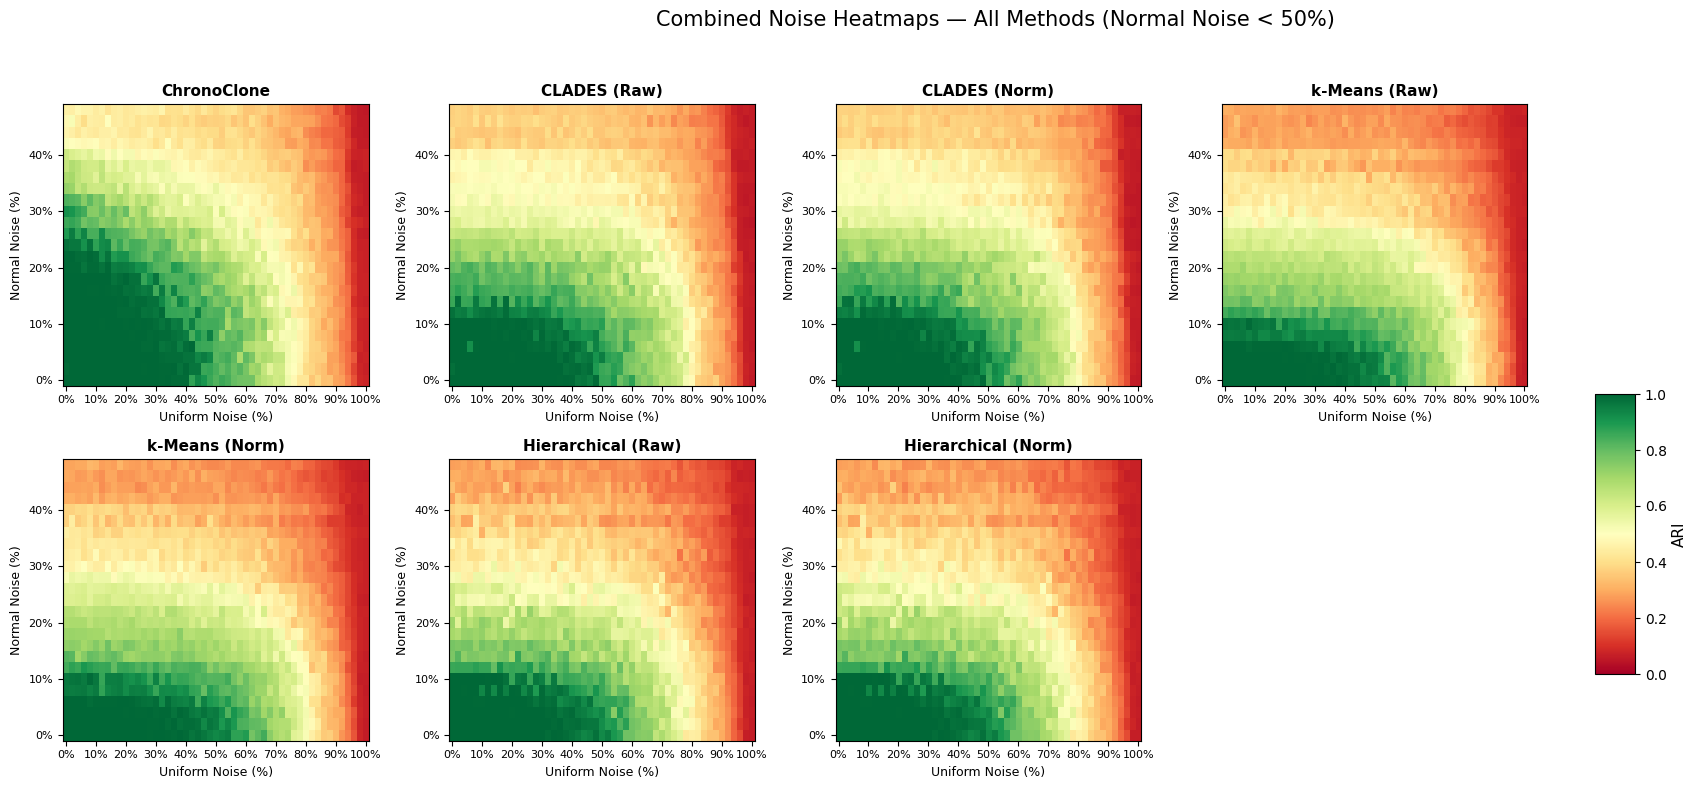

In [17]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

# Find indices where Normal Noise is under 50
# Assuming grid_levels contains numerical percentage values
y_indices = [i for i, val in enumerate(grid_levels) if val < 50]
y_slice_end = y_indices[-1] + 1 if y_indices else len(grid_levels)

# Separate x and y grid levels since they now have different lengths
grid_levels_y = grid_levels[:y_slice_end]
grid_levels_x = grid_levels

# Changed to 2x4 grid to properly accommodate 7 methods + 1 space for the colorbar
# Adjusted figsize for a better horizontal/vertical ratio
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes_flat = axes.flatten()

cmap = plt.cm.RdYlGn
norm = mcolors.Normalize(vmin=0, vmax=1)

# Step size to avoid overlapping labels
tick_step = 5 if len(grid_levels) > 10 else 1

for idx, m in enumerate(METHOD_NAMES):
    ax = axes_flat[idx]
    
    # Slice the combined_grids data to only include normal noise under 50 percent (y-axis)
    sliced_grid = combined_grids[m][:y_slice_end, :]
    
    im = ax.imshow(sliced_grid, cmap=cmap, norm=norm, origin='lower',
                   aspect='auto')

    # Commented out cell annotations to prevent overlapping text
    '''
    if len(grid_levels) <= 10:
        for i in range(len(grid_levels_y)):
            for j in range(len(grid_levels_x)):
                val = sliced_grid[i, j]
                fc  = 'white' if val < 0.4 or val > 0.8 else 'black'
                ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                        fontsize=8.5, color=fc, fontweight='bold')
    '''

    # Apply spacing to ticks to keep axes readable based on the sliced axes lengths
    ax.set_xticks(range(0, len(grid_levels_x), tick_step))
    ax.set_yticks(range(0, len(grid_levels_y), tick_step))
    ax.set_xticklabels([f'{grid_levels_x[v]}%' for v in range(0, len(grid_levels_x), tick_step)], fontsize=8)
    ax.set_yticklabels([f'{grid_levels_y[v]}%' for v in range(0, len(grid_levels_y), tick_step)], fontsize=8)
    
    ax.set_xlabel('Uniform Noise (%)', fontsize=9)
    ax.set_ylabel('Normal Noise (%)', fontsize=9)
    ax.set_title(m, fontsize=11, fontweight='bold')

# Hide any remaining panels (the 8th panel, and any others if len(METHOD_NAMES) < 7)
for idx in range(len(METHOD_NAMES), len(axes_flat)):
    axes_flat[idx].set_visible(False)

# Use the empty space on the right for the shared colorbar
cbar_ax = fig.add_axes([0.80, 0.15, 0.02, 0.35])
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cbar_ax)
cbar.set_label('ARI', fontsize=11)

plt.suptitle('Combined Noise Heatmaps — All Methods (Normal Noise < 50%)', fontsize=15, y=0.98)

# Leave space on the right so the layout doesn't overlap the manual colorbar
plt.tight_layout(rect=[0, 0, 0.78, 0.95])

# PLEASE COMMENT WHEN WRITE CODE TO SAVE FILES LIKE 'savefig()'
# Added _20260626 to the filename so it conforms to the _YYYYMMDD request
# plt.savefig('benchmarking_combined_noise_heatmaps_under50_20260626.pdf', dpi=600, bbox_inches='tight')

# Show plot directly in the JupyterLab notebook
plt.show()

## Save Results to CSV

In [16]:
# Single noise results
rows_normal  = [{'noise_pct': p, 'noise_type': 'normal',  **{m: normal_results[m][i]  for m in METHOD_NAMES}} for i, p in enumerate(all_levels)]
rows_uniform = [{'noise_pct': p, 'noise_type': 'uniform', **{m: uniform_results[m][i] for m in METHOD_NAMES}} for i, p in enumerate(all_levels)]
single_df = pd.DataFrame(rows_normal + rows_uniform)
single_df.to_csv('simulated_data/benchmarking_single_noise_results.csv', index=False)
print('Saved: simulated_data/benchmarking_single_noise_results.csv')
display(single_df)

# Combined noise results
rows_combined = []
for i, g_pct in enumerate(grid_levels):
    for j, u_pct in enumerate(grid_levels):
        row = {'normal_pct': g_pct, 'uniform_pct': u_pct}
        for m in METHOD_NAMES:
            row[m] = combined_grids[m][i, j]
        rows_combined.append(row)
combined_df = pd.DataFrame(rows_combined)
combined_df.to_csv('simulated_data/benchmarking_combined_noise_results.csv', index=False)
print('Saved: simulated_data/benchmarking_combined_noise_results.csv')
combined_df

Saved: simulated_data/benchmarking_single_noise_results.csv


,noise_pct,noise_type,ChronoClone,CLADES (Raw),CLADES (Norm),k-Means (Raw),k-Means (Norm),Hierarchical (Raw),Hierarchical (Norm)
0,0,normal,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,2,normal,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
2,4,normal,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
3,6,normal,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
4,8,normal,1.000000,1.000000,1.000000,0.960507,0.960507,1.000000,1.000000
...,...,...,...,...,...,...,...,...,...
97,92,uniform,0.244072,0.226856,0.236143,0.276600,0.282450,0.232691,0.232691
98,94,uniform,0.196060,0.192426,0.190813,0.215514,0.191554,0.189348,0.189348
99,96,uniform,0.125392,0.127355,0.129014,0.149526,0.151624,0.115875,0.115875
100,98,uniform,0.079482,0.062539,0.073760,0.084682,0.072671,0.069105,0.070686


Saved: simulated_data/benchmarking_combined_noise_results.csv


,normal_pct,uniform_pct,ChronoClone,CLADES (Raw),CLADES (Norm),k-Means (Raw),k-Means (Norm),Hierarchical (Raw),Hierarchical (Norm)
0,0,0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,0,2,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
2,0,4,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
3,0,6,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
4,0,8,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
...,...,...,...,...,...,...,...,...,...
2596,100,92,0.130803,0.090138,0.090524,0.079250,0.076969,0.080667,0.080667
2597,100,94,0.083993,0.069767,0.068985,0.074195,0.070523,0.080857,0.080857
2598,100,96,0.069500,0.064174,0.059697,0.074676,0.069212,0.068865,0.068865
2599,100,98,0.061506,0.066457,0.068939,0.072996,0.070052,0.071846,0.071846
